In [23]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.constants import Boltzmann as k_B, elementary_charge as e
from scipy.integrate import solve_ivp

T0 = 300
Tm_exp = 3695
a0 = 3.1442213e-10
n_W = 2 / a0**3
C_l = 3 * n_W * k_B

T_Ce, Ce_tab = np.loadtxt("resources/Ce_W.dat").T
T_G, G_tab = np.loadtxt("resources/G_W.dat").T
Ce = lambda T: np.interp(T, T_Ce * 1e4, Ce_tab * 1e5)
G = lambda T: np.interp(T, T_G * 1e4, G_tab * 1e17)

rho_W = lambda T: (
    1e-8 * np.polyval([2.0790e-13, -1.8517e-9, 7.8260e-6, 1.9274e-2, -0.9680], T)
)
rho_He = lambda T: 2.65e-6 * (1 + T / 15000)

## Electron–phonon relaxation and heating rate

$$\tau_{\mathrm{e-ph}}=\frac{C_e C_l}{G(C_e+C_l)}.$$

$$C_e(T_e)\frac{dT_e}{dt}=j^2\rho_{\mathrm{e}}(T_l)-G(T_e)(T_e-T_l),$$

$$C_l\frac{dT_l}{dt}=G(T_e)(T_e-T_l),$$

where $T_e$ and $T_l$ are the electron and lattice temperatures, $C_e$ and $C_l$ are the corresponding heat capacities, $G$ is the electron–phonon coupling factor, $j$ is the current density, and $\rho_{\mathrm{e}}$ is the electrical resistivity. The lattice heat capacity is approximated as $C_l=3n_{\mathrm{W}}k_{\mathrm{B}}$, with $n_{\mathrm{W}}=2/a_0^3$.

The TTM equations are solved for constant current densities of 1.1–3.5 GA $\text{cm}^{-2}$, with initial temperatures $T_e(0)=T_l(0)=300$ K. The average heating rate is calculated as $\bar{\alpha}=(3695-300)/t_h$, where $t_h$ is the time required for the lattice to reach the experimental melting temperature of W (3695 K).

In [24]:
T = np.linspace(T0, 20000, 19701)
tau = Ce(T) * C_l / (G(T) * (Ce(T) + C_l)) / 1e-12

print(f"tau_e-ph = {tau.min():.3f}–{tau.max():.3f} ps")
print(f"Maximum at {T[tau.argmax()]:.0f} K")

tau_e-ph = 0.155–1.910 ps
Maximum at 4541 K


In [25]:
def solve_ttm(j, rho_e):
    def rhs(t, y):
        Te, Tl = y
        Q = G(Te) * (Te - Tl)
        return 1e-12 * np.array([(j**2 * rho_e(Tl) - Q) / Ce(Te), Q / C_l])

    def melting(t, y):
        return y[1] - Tm_exp

    melting.terminal, melting.direction = True, 1
    sol = solve_ivp(
        rhs, (0, 1000), [T0, T0], method="Radau", events=melting, rtol=1e-7, atol=1e-6
    )
    return sol.t[-1], sol.y[0, -1]


j_values = np.linspace(1.1, 3.5, 25)
rows = []
for name, rho_e in [("Bulk W", rho_W), ("W-He fibre", rho_He)]:
    for j in j_values:
        th, Te = solve_ttm(j * 1e13, rho_e)
        rows.append([name, j, th, (Tm_exp - T0) / th, Te])

ttm = pd.DataFrame(
    rows, columns=["Material", "j_GA_cm2", "th_ps", "alpha_K_ps", "Te_final_K"]
)
display(ttm[ttm.j_GA_cm2.isin([1.1, 3.5])].round(2).reset_index(drop=True))

,Material,j_GA_cm2,th_ps,alpha_K_ps,Te_final_K
0,Bulk W,1.1,244.18,13.90,4038.65
1,Bulk W,3.5,27.48,123.52,5635.29
2,W-He fibre,1.1,29.55,114.89,4513.03
3,W-He fibre,3.5,4.22,804.79,7509.07


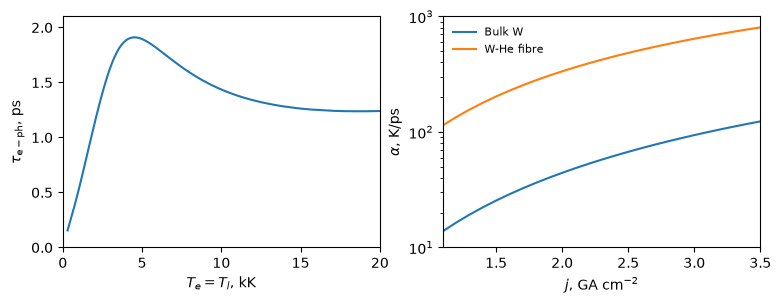

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(9.0, 3))
ax[0].plot(T / 1000, tau, lw=1.5)
ax[0].set(
    xlabel=r"$T_e=T_l$, kK",
    ylabel=r"$\tau_{\mathrm{e-ph}}$, ps",
    xlim=(0, 20),
    ylim=(0, 2.1),
)
for name, d in ttm.groupby("Material", sort=False):
    ax[1].plot(d.j_GA_cm2, d.alpha_K_ps, lw=1.5, label=name)
ax[1].set(
    xlabel=r"$j$, GA cm$^{-2}$",
    ylabel=r"$\alpha$, K/ps",
    xlim=(1.1, 3.5),
    yscale="log",
    ylim=(10, 1000),
)
ax[1].legend(frameon=False, fontsize=8)
for a in ax:
    a.grid(False)
plt.show()